# Crossmatch performance by tool (2026 rerun on SLAC SDF)

Reads the per-run JSON files written by `run_benchmark.py` under `results/<config>/<step>/{lsdb_w<w>,astropy,smatch}_run<i>.json`
and reproduces the layout of the Feb 2025 figure (`../lsdb_crossmatch_benchmarking/plot_benchmark.ipynb`).

Plotted quantity per tool, per ladder step:
* **LSDB (w worker threads)** = wall time of `crossmatch(...).map_partitions(len).compute()` (reads + matches).
* **Astropy** = pyarrow read of the same ZTF / Gaia / Gaia-margin files + Gaia/margin merge + cone filter + `SkyCoord`
  construction + `match_coordinates_sky` + distance cut + parquet write (native mode, 2026-09-17; the 2025 run excluded
  `SkyCoord` construction).
* **smatch** = the same pyarrow read + Gaia/margin merge + cone filter + `smatch.match(ztf, r, gaia, maxmatch=1)` + parquet
  write (native mode). With `--smatch-config`, the plotted series passes the Gaia side in random order (smatch's HEALPix
  tree is an unbalanced BST that HATS order degenerates into a chain, see NOTES.md); the plain call stays as `smatch_plain`.

Point = median over repeats; error bars = 10th/90th percentile; x = number of crossmatched rows, or of left-catalog
(ZTF) rows in the selection when the notebook was generated with `--x left`.


In [1]:
import json
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS = Path("results")
# (config, series, step) triples left out of the curves. Both were run while the 16 x 8 GB Dask workers
# hit their 95% memory budget and were restarted (40 restarts in total, run_all log 18:00-20:45 on 2026-09-15):
# tasks were recomputed inside the timed region and the two repeats at pixels:1791 disagree by 2x
# (852 s vs 1668 s). The JSONs stay under results/default/ and are listed in the "excluded" table below.
EXCLUDE = {("default", "lsdb_16", "pixels:1024"), ("default", "lsdb_16", "pixels:1791")}
CONFIG_ALL = "cones"   # ZTF default columns + 27 Gaia columns
CONFIG_RADEC = "cones_radec"   # only ra, dec on both sides
CONFIG_SLURM = "none"  # default columns, the largest steps re-run on a dedicated SLURM node (optional)
OUT_PNG = "crossmatching-performance-2026-cones-smatch-both.png"
X_AXIS = "left"  # "matched": crossmatched rows; "left": rows of the left catalog (ZTF) in the selection; "read": rows of the partitions touched
XCOL = {"matched": "rows", "left": "left", "read": "read"}[X_AXIS]
STILTS_SERIES = "xmatch"  # "io": conversions + tmatch2; "xmatch": tmatch2 only
CONFIG_SMATCH = "cones_smatch_shuffled"  # results/<config> with smatch's second argument in random order ("none": plot the main config's smatch)
SMATCH_PLAIN = "dotted"  # "dotted": also draw the main config's plain-call smatch series


INFO:numexpr.utils:Note: detected 128 virtual cores but NumExpr set to maximum of 64, check "NUMEXPR_MAX_THREADS" environment variable.


INFO:numexpr.utils:Note: NumExpr detected 128 cores but "NUMEXPR_MAX_THREADS" not set, so enforcing safe limit of 16.


INFO:numexpr.utils:NumExpr defaulting to 16 threads.


In [2]:
def load_runs(config):
    """All per-(step, component, repeat) records of one config, plus its settings."""
    recs = [json.loads(f.read_text()) for f in sorted((RESULTS / config).glob("*/*_run*.json"))]
    settings = json.loads((RESULTS / config / "settings.json").read_text())
    return recs, settings


def series_from_recs(recs, config):
    """-> {series_key: {step: [(time, result_length, left_rows, left_rows_read), ...]}}; (config, series, step) in EXCLUDE are dropped"""
    out = defaultdict(lambda: defaultdict(list))
    for r in recs:
        step = r["step"]
        if r["tool"] == "lsdb":
            xm = r.get("lsdb_crossmatch")
            if xm and xm.get("result_length") is not None and (config, f"lsdb_{r['workers']}", step) not in EXCLUDE:
                out[f"lsdb_{r['workers']}"][step].append((xm["time"], xm["result_length"], r.get("left_rows"), r.get("left_rows_read")))
        elif r.get("ok"):
            tool = r["tool"]; ms = r["measurements"]
            # everything a user must do besides the match call itself: pyarrow reads (or STILTS conversions), joining Gaia with
            # its margin, the cone filter, SkyCoord construction, writing the result
            io = sum(v["time"] for k, v in ms.items() if isinstance(v, dict)
                     and (k.endswith("_pyarrow") or k.endswith("_io") or k.endswith("_write") or k in ("cone_filter", "merge_right", "skycoords")))
            xm = ms[f"{tool}_xmatch"]
            left = r.get("left_rows", ms.get("left_rows")); read = r.get("left_rows_read")
            out[f"{tool}+io"][step].append((io + xm["time"], xm["result_length"], left, read))
            out[f"{tool}_xmatch_only"][step].append((xm["time"], xm["result_length"], left, read))
            out["pyarrow_io"][step].append((io, xm["result_length"], left, read))
    return out


def failures(recs):
    """Steps where astropy/smatch did not finish (out of memory or skipped)."""
    rows = [{"step": r["step"], "tool": r["tool"], "run": r["run"], "oom": r.get("oom"), "skipped": r.get("skipped"),
             "error": str(r.get("error", ""))[-120:]} for r in recs if r["tool"] != "lsdb" and not r.get("ok")]
    return pd.DataFrame(rows)


def aggregate(series):
    """-> {series_key: DataFrame[step, n, rows, left, median, q10, q90]} sorted by the x column"""
    agg = {}
    for key, per_step in series.items():
        rows = []
        for step, vals in per_step.items():
            t = np.array([v[0] for v in vals]); n = np.array([v[1] for v in vals])
            left = [v[2] for v in vals if v[2] is not None]; read = [v[3] for v in vals if v[3] is not None]
            rows.append({"step": step, "n": len(t), "rows": int(np.median(n)), "left": int(np.median(left)) if left else None,
                         "read": int(np.median(read)) if read else None,
                         "median": np.median(t), "q10": np.quantile(t, 0.1), "q90": np.quantile(t, 0.9)})
        df = pd.DataFrame(rows)
        if XCOL in ("left", "read") and df[XCOL].isna().any():
            raise ValueError(f"{key}: {XCOL} rows missing for steps {df.loc[df[XCOL].isna(), 'step'].tolist()} (old results?)")
        agg[key] = df.sort_values(XCOL).reset_index(drop=True)
    return agg


recs_all, settings_all = load_runs(CONFIG_ALL)
agg = aggregate(series_from_recs(recs_all, CONFIG_ALL))
settings_slurm = None
for cfg, suffix in ((CONFIG_RADEC, "radec"), (CONFIG_SLURM, "slurm")):
    try:
        recs_cfg, settings_cfg = load_runs(cfg)
    except FileNotFoundError:
        print(f"no {cfg} config")
        continue
    if suffix == "slurm":
        settings_slurm = settings_cfg
    for k, df in aggregate(series_from_recs(recs_cfg, cfg)).items():
        if k.startswith("lsdb_"):
            agg[f"{k}_{suffix}"] = df
settings_smatch = None
if CONFIG_SMATCH != "none":
    # the shuffled-input smatch run replaces the plotted smatch series; the plain call stays as smatch_plain
    recs_sm, settings_smatch = load_runs(CONFIG_SMATCH)
    agg_sm = aggregate(series_from_recs(recs_sm, CONFIG_SMATCH))
    for k in ("smatch+io", "smatch_xmatch_only"):
        if k in agg:
            agg[k.replace("smatch", "smatch_plain", 1)] = agg.pop(k)
        if k in agg_sm:
            agg[k] = agg_sm[k]
print(sorted(agg))
failures(recs_all)


no none config
['astropy+io', 'astropy_xmatch_only', 'lsdb_1', 'lsdb_16', 'lsdb_16_radec', 'lsdb_4', 'pyarrow_io', 'scipy+io', 'scipy_xmatch_only', 'smatch+io', 'smatch_plain+io', 'smatch_plain_xmatch_only', 'smatch_xmatch_only', 'stilts+io', 'stilts_xmatch_only']


,step,tool,run,oom,skipped,error
0,cone:23931.84,smatch,0,False,None,killed: ran longer than the 1800 s time cap
1,cone:23931.84,smatch,1,None,an earlier step ran longer than the 1800 s tim...,
2,cone:23931.84,smatch,2,None,an earlier step ran longer than the 1800 s tim...,
3,cone:44133.7,smatch,0,None,an earlier step ran longer than the 1800 s tim...,
4,cone:44133.7,smatch,1,None,an earlier step ran longer than the 1800 s tim...,
5,cone:44133.7,smatch,2,None,an earlier step ran longer than the 1800 s tim...,
6,cone:75730.94,astropy,0,True,None,killed: RSS 128.1 GiB > cap
7,cone:75730.94,astropy,1,None,an earlier step ran out of memory,
8,cone:75730.94,astropy,2,None,an earlier step ran out of memory,


In [3]:
# Runs excluded from the curves (see EXCLUDE above): kept on disk, shown here
excluded = pd.DataFrame(
    [{"config": CONFIG_ALL, "step": r["step"], "workers": r["workers"], "run": r["run"],
      "time_s": round(r["lsdb_crossmatch"]["time"], 1), "rows": r["lsdb_crossmatch"]["result_length"]}
     for r in recs_all if r["tool"] == "lsdb" and (CONFIG_ALL, f"lsdb_{r['workers']}", r["step"]) in EXCLUDE]
)
excluded


""


In [4]:
# result_length must agree across tools for every step (a mismatch is a bug, not noise)
check = {}
for key, df in agg.items():
    if key.endswith("_xmatch_only") or key == "pyarrow_io":
        continue
    check[key] = df.set_index("step")["rows"]
pd.DataFrame(check)


,lsdb_16,lsdb_1,lsdb_4,astropy+io,scipy+io,stilts+io,lsdb_16_radec,smatch_plain+io,smatch+io
step,,,,,,,,,
cone:138355.8,198955959,198955959,198955959,NaN,NaN,NaN,198955959,NaN,NaN
cone:13894.98,1373233,1373233,1373233,1373233.0,1373233.0,1373233.0,1373233,1373232.0,1373232.0
cone:15.32955,0,0,0,0.0,0.0,0.0,0,0.0,0.0
cone:1563.811,14065,14065,14065,14065.0,14065.0,14065.0,14065,14065.0,14065.0
cone:165.5816,36,36,36,36.0,36.0,36.0,36,36.0,36.0
cone:23931.84,4110321,4110321,4110321,4110321.0,4110321.0,4110321.0,4110321,NaN,4110320.0
cone:254.488,116,116,116,116.0,116.0,116.0,116,116.0,116.0
cone:26.51309,0,0,0,0.0,0.0,0.0,0,0.0,0.0
cone:2605.741,41921,41921,41921,41921.0,41921.0,41921.0,41921,41921.0,41921.0


In [5]:
# Left-catalog rows per step (identical for every tool by construction; the x axis when X_AXIS == "left")
pd.DataFrame({k: df.set_index("step")["left"] for k, df in agg.items() if not k.endswith("_xmatch_only") and k != "pyarrow_io"})


,lsdb_16,lsdb_1,lsdb_4,astropy+io,scipy+io,stilts+io,lsdb_16_radec,smatch_plain+io,smatch+io
step,,,,,,,,,
cone:138355.8,1000000093,1000000093,1000000093,NaN,NaN,NaN,1000000093,NaN,NaN
cone:13894.98,10000004,10000004,10000004,10000004.0,10000004.0,10000004.0,10000004,10000004.0,10000004.0
cone:15.32955,3,3,3,3.0,3.0,3.0,3,3.0,3.0
cone:1563.811,100000,100000,100000,100000.0,100000.0,100000.0,100000,100000.0,100000.0
cone:165.5816,300,300,300,300.0,300.0,300.0,300,300.0,300.0
cone:23931.84,30000015,30000015,30000015,30000015.0,30000015.0,30000015.0,30000015,NaN,30000015.0
cone:254.488,1000,1000,1000,1000.0,1000.0,1000.0,1000,1000.0,1000.0
cone:26.51309,10,10,10,10.0,10.0,10.0,10,10.0,10.0
cone:2605.741,300000,300000,300000,300000.0,300000.0,300000.0,300000,300000.0,300000.0


In [6]:
# Median-time table (seconds), indexed by step: the x value can repeat between steps (rows read) and a series may end early
tbl = pd.DataFrame({k: v.set_index("step")["median"].round(2) for k, v in agg.items() if not k.endswith("_xmatch_only")})
tbl.insert(0, XCOL, pd.concat([v.set_index("step")[XCOL] for v in agg.values()]).groupby(level=0).first())
tbl.sort_values(XCOL)


,left,lsdb_16,lsdb_1,lsdb_4,astropy+io,pyarrow_io,scipy+io,stilts+io,lsdb_16_radec,smatch_plain+io,smatch+io
step,,,,,,,,,,,
cone:8.437894,1,0.95,1.41,1.01,0.87,0.71,0.98,1.73,0.69,8.99,1.33
cone:15.32955,3,1.03,1.43,1.03,0.85,0.70,1.02,1.76,0.73,9.38,1.33
cone:26.51309,10,1.01,1.50,1.10,0.86,0.69,0.96,1.69,0.71,9.49,1.31
cone:58.038,30,1.04,1.48,0.96,0.88,0.70,0.97,1.77,0.70,8.77,1.33
cone:98.72446,100,1.07,1.41,1.10,0.85,0.71,0.99,1.81,0.90,8.83,1.34
cone:165.5816,300,1.10,1.39,1.03,0.87,0.71,0.98,1.83,0.81,8.80,1.33
cone:254.488,1000,1.08,1.74,1.22,0.85,0.73,1.01,1.88,0.70,9.19,1.34
cone:372.8226,3000,1.15,1.50,1.37,0.87,0.71,0.98,1.87,0.75,9.44,1.37
cone:587.3358,10000,1.07,1.44,1.06,0.89,0.71,1.01,1.97,0.71,9.88,1.33


wrote crossmatching-performance-2026-cones-smatch-both.png


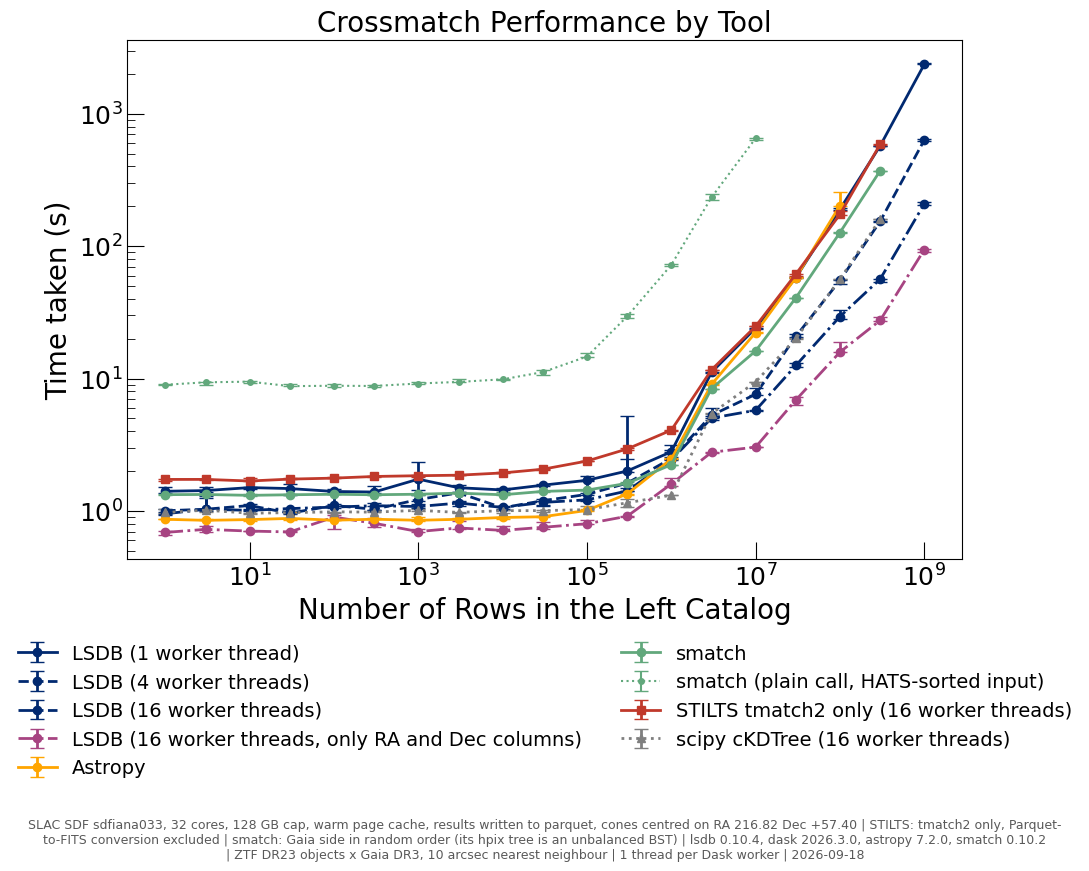

In [7]:
plt.style.use("default")
plt.rcParams.update({"font.size": 16, "axes.labelsize": 20, "axes.titlesize": 20, "legend.fontsize": 14})
LEGEND_POS = "below"
fig, ax = plt.subplots(1, 1, figsize=(11, 7.5 if LEGEND_POS == "inside" else 8.8))

s = settings_all
scipy_threads = s.get("tool_threads") or s["n_cpus"]          # before --tool-threads existed scipy used every allowed core
stilts_threads = s.get("tool_threads") or min(6, s["n_cpus"])  # STILTS runner=parallel defaults to min(6, cores)
plotting_args = {
    "lsdb_1": dict(marker="o", label="LSDB (1 worker thread)", c="#012970", ls="-", lw=2),
    "lsdb_4": dict(marker="o", label="LSDB (4 worker threads)", c="#012970", ls="--", lw=2),
    "lsdb_16": dict(marker="o", label="LSDB (16 worker threads)", c="#012970", ls="-.", lw=2),
    "lsdb_16_radec": dict(marker="o", label="LSDB (16 worker threads, only RA and Dec columns)", c="#A74482", ls="-.", lw=2),
    "lsdb_16_slurm": dict(marker="s", label="LSDB (16 worker threads, dedicated SLURM node)", c="#012970", ls=":", lw=2, ms=9),
    "astropy+io": dict(marker="o", label="Astropy", c="orange", ls="-", lw=2),
    "smatch+io": dict(marker="o", label="smatch", c="#62A87C", ls="-", lw=2),  # the shuffled-input call when --smatch-config is set (footer note says so)
    "smatch_plain+io": dict(marker="o", label="smatch (plain call, HATS-sorted input)", c="#62A87C", ls=":", lw=1.5, ms=4),
    "stilts+io": dict(marker="s", label=f"STILTS tmatch2 (TOPCAT, {stilts_threads} worker threads)", c="#C0392B", ls="-", lw=2),
    "stilts_xmatch_only": dict(marker="s", label=f"STILTS tmatch2 only ({stilts_threads} worker threads)", c="#C0392B", ls="-", lw=2),
    "scipy+io": dict(marker="^", label=f"scipy cKDTree ({scipy_threads} worker threads)", c="#7F7F7F", ls=":", lw=2),
}
for key, kw in plotting_args.items():
    if key not in agg or key == ("stilts_xmatch_only" if STILTS_SERIES == "io" else "stilts+io"):
        continue
    if key == "smatch_plain+io" and SMATCH_PLAIN != "dotted":
        continue
    d = agg[key]
    x, y = d[XCOL].to_numpy(), d["median"].to_numpy()
    ax.errorbar(x, y, [y - d["q10"].to_numpy(), d["q90"].to_numpy() - y], capsize=5, **kw)

ax.set_xscale("log"); ax.set_yscale("log")
ax.tick_params(axis="both", which="major", labelsize=18, length=12, direction="in")
ax.tick_params(axis="both", which="minor", labelsize=12, length=6, direction="in")
ax.set_xlabel({"matched": "Number of Crossmatched Rows", "left": "Number of Rows in the Left Catalog",
               "read": "Number of Left-Catalog Rows Read (partitions touched)"}[X_AXIS])
ax.set_ylabel("Time taken (s)")
ax.set_title("Crossmatch Performance by Tool")
if LEGEND_POS == "inside":
    ax.legend(loc="upper left", ncol=2, fontsize=13 if 2 > 1 else 14, columnspacing=1.2)
else:
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=14, frameon=False, columnspacing=2.0)

v = s["versions"]
threads = {str(r["workers"]): r["threads_per_worker"] for r in recs_all if r["tool"] == "lsdb"}
steps_all = {r["step"] for r in recs_all}
seed = s["seed_partition"]
sel = (f", cones centred on RA {seed['ra']:.2f} Dec {seed['dec']:+.2f}" if all(st.startswith("cone") for st in steps_all) else "")
mode = "results written to parquet" if s.get("output_mode") == "write" else "results counted in memory"
band = f", ZTF partitions {s['rows_band'][0]/1e6:.1f}-{s['rows_band'][1]/1e6:.1f}M rows" if s.get("rows_band") else ""
stilts_note = " | STILTS: tmatch2 only, Parquet-to-FITS conversion excluded" if STILTS_SERIES == "xmatch" else ""
stilts_note += " | smatch: Gaia side in random order (its hpix tree is an unbalanced BST)" if settings_smatch is not None else ""
caption = (f"SLAC SDF {s['hostname']}, {s['n_cpus']} cores, {s['mem_cap_gb']:.0f} GB cap, warm page cache, {mode}{band}{sel}{stilts_note} | "
           f"lsdb {v['lsdb']}, dask {v['dask']}, astropy {v['astropy']}, smatch {v['smatch']} | "
           f"ZTF DR23 objects x Gaia DR3, {s['radius_arcsec']:g} arcsec nearest neighbour | "
           f"{threads.get('1', 1)} thread per Dask worker | {s['timestamp_utc'][:10]}")
if settings_slurm is not None:
    caption += (f" | squares: {settings_slurm['hostname']}, {settings_slurm['n_cpus']} cores, "
                f"{settings_slurm['mem_cap_gb']:.0f} GB cap")
import textwrap
fig.text(0.5, 0.005, textwrap.fill(caption, 160), ha="center", va="bottom", fontsize=9, color="0.35")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(OUT_PNG, dpi=300)
print("wrote", OUT_PNG)
